In [3]:
import pandas as pd
import re
import sklearn
from matplotlib import pyplot as plt
import random
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn import tree

In [7]:
import sys
!{sys.executable} -m pip install scikit-learn matplotlib

#### Chargement du corpus reddit et journaux

In [5]:
import sklearn
print(sklearn.__version__)

1.6.1


In [7]:
import pandas as pd
df_data=pd.read_excel("df_reddit_news.xlsx")

In [9]:
print(f'Taille du corpus avant suppression des doublons: {len(df_data)}')

Taille du corpus avant suppression des doublons: 5251


In [20]:
df_data.head()

,Unnamed: 0,text,annotation
0,0,Les français aiment-ils tellement se plaindre ...,1
1,1,"Retour en Iran, chute du régime... Ce qu’il fa...",0
2,2,Sébastien Lecornu a présenté sa démission à l’...,0
3,3,"« Ce qui tue les automobilistes, c’est l’assis...",0
4,4,Test : quel cadeau de Noël raté êtes-vous ? |N...,1


In [22]:
print(f'Taille du corpus reddit après suppression des doublons: {len(df_data)}')

Taille du corpus reddit après suppression des doublons: 5251


In [26]:
neg=df_data[df_data["annotation"]==0]
print(f"Nombre d'instances négatives: {len(neg)}")

Nombre d'instances négatives: 2947


In [30]:
pos=df_data[df_data["annotation"]==1]
print(f"Nombre d'instances positives: {len(pos)}")

Nombre d'instances positives: 2304


In [32]:
print(len(neg)+len(pos))

5251


In [34]:
df_data.value_counts(subset="annotation")

annotation
0    2947
1    2304
Name: count, dtype: int64

### Prétraitement des données

In [36]:
# fonctions pour nettoyage des données
def rep_urls(text):
    text = re.sub(r'https?://\S+|www\.\S+', 'URL', text)
    return text

In [38]:
def rep_gif(text):
    text=re.sub(r'!gif\b.*', 'GIF_TOKEN', text)
    return text

In [40]:
import re

def clean_text(text):
    if not isinstance(text, str):
        return text

    # Newlines and tabs
    text = text.replace("\n", " ")
    text = text.replace("\t", " ")

    # Non-breaking spaces
    text = text.replace("\xa0", " ")

    # Optional: remove other escaped hex artifacts that appear literally
    text = re.sub(r"\\x[a-fA-F0-9]{2}", " ", text)

    # Collapse multiple spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

##### Nettoyage du corpus de reddits

In [44]:
df_data["clean_text"] = df_data["text"].apply(clean_text)

In [48]:
df_data["clean_text"]=df_data["clean_text"].apply(rep_urls)

In [50]:
df_data["clean_text"]=df_data["clean_text"].apply(rep_gif)

In [54]:
df_data["annotation"].value_counts()

annotation
0    2947
1    2304
Name: count, dtype: int64

In [56]:
df_data

,Unnamed: 0,text,annotation,clean_text
0,0,Les français aiment-ils tellement se plaindre ...,1,Les français aiment-ils tellement se plaindre ...
1,1,"Retour en Iran, chute du régime... Ce qu’il fa...",0,"Retour en Iran, chute du régime... Ce qu’il fa..."
2,2,Sébastien Lecornu a présenté sa démission à l’...,0,Sébastien Lecornu a présenté sa démission à l’...
3,3,"« Ce qui tue les automobilistes, c’est l’assis...",0,"« Ce qui tue les automobilistes, c’est l’assis..."
4,4,Test : quel cadeau de Noël raté êtes-vous ? |N...,1,Test : quel cadeau de Noël raté êtes-vous ? |N...
...,...,...,...,...
5246,5246,Interdiction des réseaux sociaux aux moins de ...,0,Interdiction des réseaux sociaux aux moins de ...
5247,5247,Fiat 500 : cet atelier italien électrifie des ...,0,Fiat 500 : cet atelier italien électrifie des ...
5248,5248,Affaire Epstein : une commission d’enquête par...,0,Affaire Epstein : une commission d’enquête par...
5249,5249,Le président de SOS racisme mis en examen pour...,0,Le président de SOS racisme mis en examen pour...


##### Diviser les données en données de test et de dev

In [58]:
df_data = df_data.sample(frac=1, random_state=1).reset_index(drop=True)

In [60]:
from sklearn.model_selection import train_test_split

train_df,temp_df=train_test_split(
    df_data,
    test_size=0.2,
    random_state=42,
    stratify=df_data["annotation"])

dev_df,test_df=train_test_split(
    temp_df,
    test_size=0.5,
    random_state=42,
    stratify=temp_df["annotation"])

In [64]:
vectorizer = TfidfVectorizer()
X_train = vectorizer.fit_transform(train_df["text"])
X_dev   = vectorizer.transform(dev_df["text"])
X_test  = vectorizer.transform(test_df["text"])

In [66]:
pip freeze > requirements_DT.txt

Note: you may need to restart the kernel to use updated packages.


In [68]:
y_train=train_df["annotation"]
y_dev=dev_df["annotation"]
y_test=test_df["annotation"]

In [70]:
clf_tree=DecisionTreeClassifier(criterion="entropy")
clf_tree.fit(X_train,y_train)

DecisionTreeClassifier(criterion='entropy')

[Text(0.7168367346938775, 0.9285714285714286, 'x[14285] <= 0.031\nentropy = 0.989\nsamples = 4200\nvalue = [2357, 1843]\nclass = non_sarcastic'),
 Text(0.4744897959183674, 0.7857142857142857, 'x[16279] <= 0.017\nentropy = 0.982\nsamples = 4024\nvalue = [2333, 1691]\nclass = non_sarcastic'),
 Text(0.5956632653061225, 0.8571428571428572, 'True  '),
 Text(0.2755102040816326, 0.6428571428571429, 'x[6524] <= 0.037\nentropy = 0.99\nsamples = 3725\nvalue = [2077, 1648]\nclass = non_sarcastic'),
 Text(0.15306122448979592, 0.5, 'x[17006] <= 0.078\nentropy = 0.999\nsamples = 2038\nvalue = [983, 1055]\nclass = sarcastic'),
 Text(0.08163265306122448, 0.35714285714285715, 'x[5556] <= 0.105\nentropy = 0.996\nsamples = 1931\nvalue = [895, 1036]\nclass = sarcastic'),
 Text(0.04081632653061224, 0.21428571428571427, 'x[10676] <= 0.061\nentropy = 0.994\nsamples = 1888\nvalue = [855, 1033]\nclass = sarcastic'),
 Text(0.02040816326530612, 0.07142857142857142, '\n  (...)  \n'),
 Text(0.061224489795918366, 0

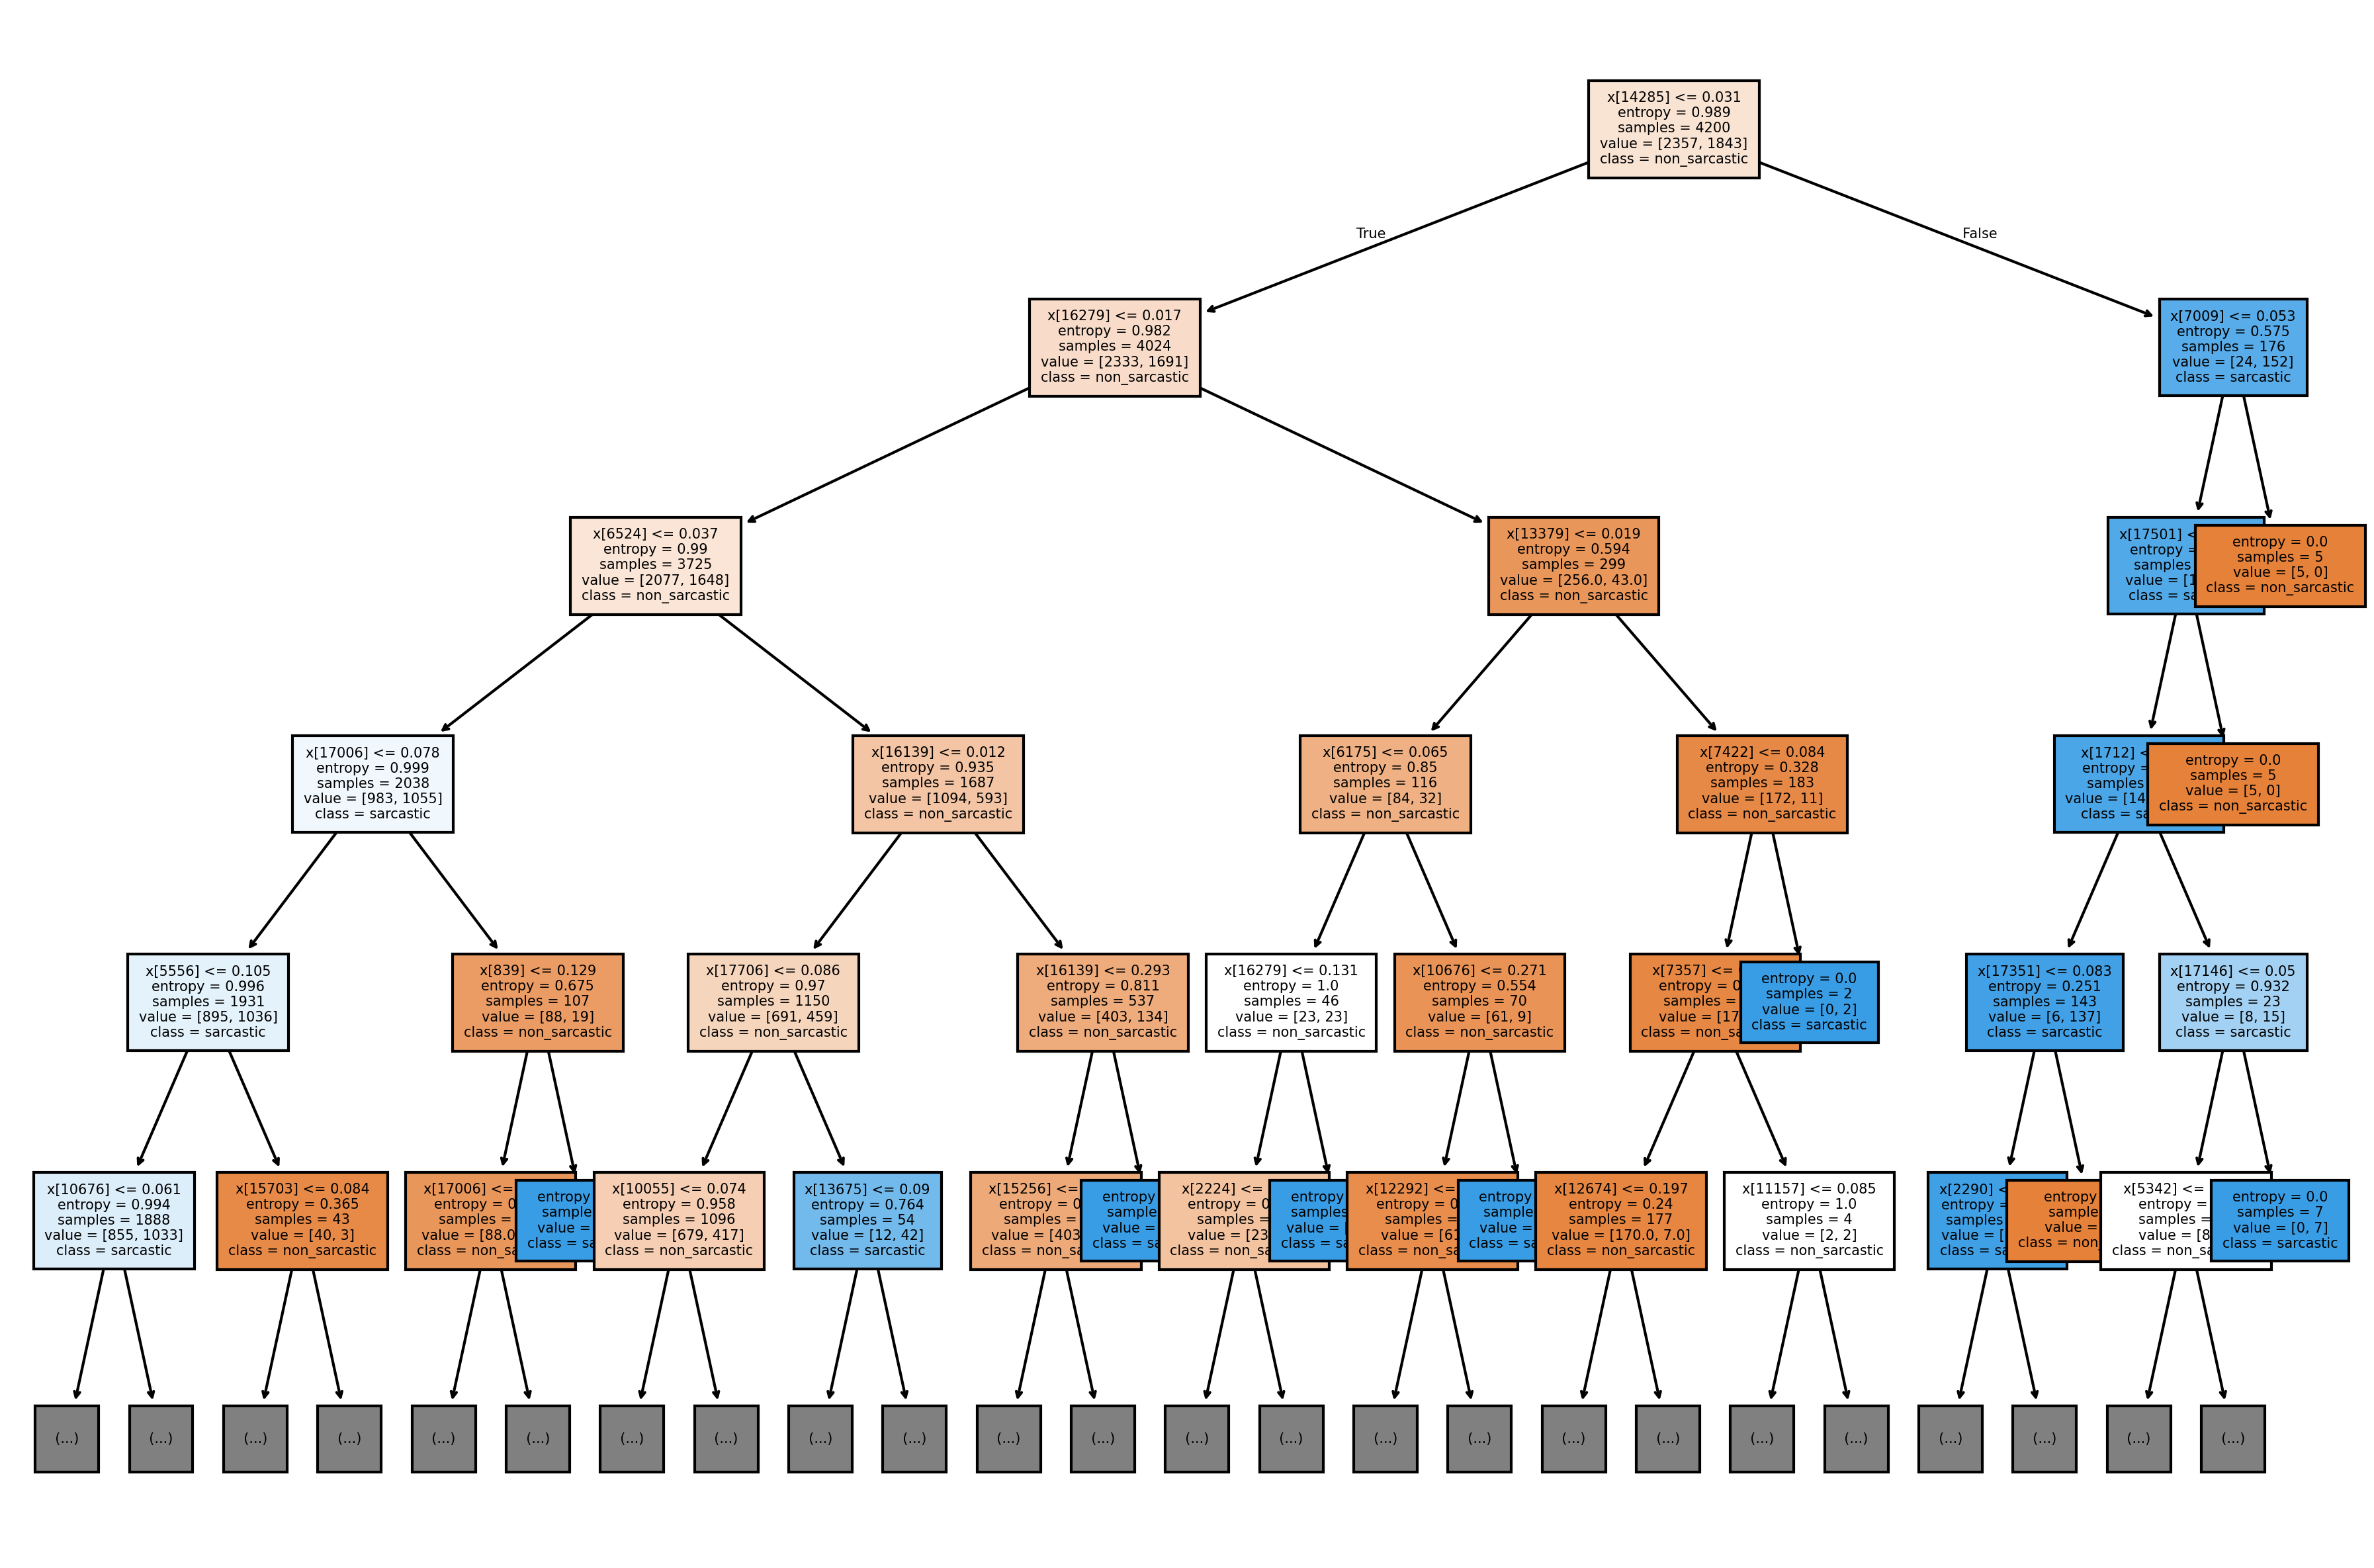

In [72]:
fig, axes = plt.subplots(nrows = 1,ncols = 1,figsize = (15,10), dpi=300)

tree.plot_tree(clf_tree, max_depth=5,
           class_names=['non_sarcastic', 'sarcastic'],
           filled = True, fontsize=5)

In [74]:
dev_pred=clf_tree.predict(X_dev)

In [76]:
print("Classification report pour les données de développement")
print("---------------------------------------------------------------")
print(classification_report(y_dev,dev_pred, target_names=["non sarcastic","sarcastic"]))

Classification report pour les données de développement
---------------------------------------------------------------
               precision    recall  f1-score   support

non sarcastic       0.72      0.66      0.69       295
    sarcastic       0.61      0.66      0.63       230

     accuracy                           0.66       525
    macro avg       0.66      0.66      0.66       525
 weighted avg       0.67      0.66      0.66       525



In [78]:
test_pred=clf_tree.predict(X_test)

In [80]:
print("Classification report pour les données de test")
print()
print("-------------------------------------------------------------")
print(classification_report(y_test,test_pred,target_names=["non sarcastic","sarcasticc"]))

Classification report pour les données de test

-------------------------------------------------------------
               precision    recall  f1-score   support

non sarcastic       0.70      0.71      0.70       295
   sarcasticc       0.62      0.61      0.61       231

     accuracy                           0.66       526
    macro avg       0.66      0.66      0.66       526
 weighted avg       0.66      0.66      0.66       526



In [84]:
df_data["annotation"].value_counts()

annotation
0    2947
1    2304
Name: count, dtype: int64

In [92]:
import pandas as pd

results = pd.DataFrame({
    "texte": X_test,
    "y_true": y_test,
    "y_pred": test_pred
})

In [96]:
results.to_csv("final_memoire/resultats_DT.csv")

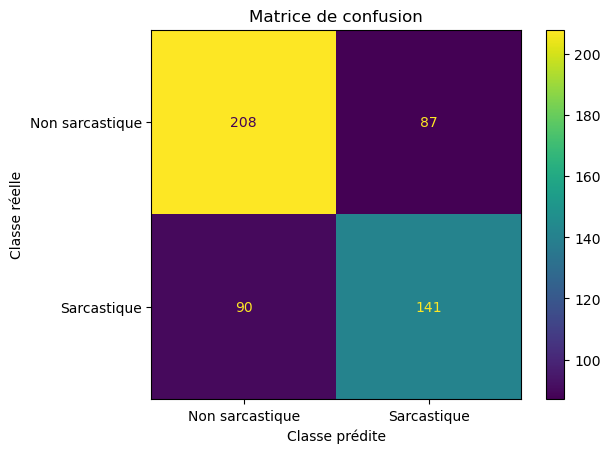

In [86]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Calcul de la matrice de confusion
cm = confusion_matrix(y_test, test_pred)

# Affichage
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Non sarcastique", "Sarcastique"]
)

disp.plot(values_format="d")

plt.title("Matrice de confusion")
plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")
plt.show()